# Can a Neural Network Predict Tomorrow's Bitcoin Price?

Price-forecasting tutorials often end with a chart where the predicted line hugs the real one. This notebook checks how much of that is real skill.

**Data:** daily Bitcoin prices in US dollars (BTC/USDT on Binance) from January 2018 to October 2026, from Binance's public market data. It's saved next to this notebook as `btc_usdt_daily.csv`, so no account or key is needed.

**Plan:**
1. Look at the price and the trading volume.
2. Split the volume into trend, weekly rhythm, and unusual days.
3. Train an LSTM neural network to predict the next day, and compare it with the simplest guess: tomorrow equals today.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mplfinance as mpf
from statsmodels.tsa.seasonal import seasonal_decompose
import tensorflow as tf
from tensorflow.keras import layers, models

tf.keras.utils.set_random_seed(42)
plt.rcParams["figure.figsize"] = (14, 5)

## 1. The data

In [2]:
btc = pd.read_csv("btc_usdt_daily.csv", parse_dates=["date"], index_col="date")
print(f"{len(btc):,} days, {btc.index.min():%b %Y} to {btc.index.max():%b %Y}")
btc.tail()

3,226 days, Jan 2018 to Oct 2026


,open,high,low,close,volume,quote_volume,trades
date,,,,,,,
2026-10-27,80150.56,81300.00,79506.00,80909.77,13230.65,1.062257e+09,2450945
2026-10-28,80909.77,81823.00,80397.14,81343.50,13109.37,1.062453e+09,2544713
2026-10-29,81343.51,81971.00,77910.00,77991.89,23832.18,1.905695e+09,4200501
2026-10-30,77991.89,78804.01,76325.98,77368.77,24295.95,1.883011e+09,4894043
2026-10-31,77368.76,77796.01,77114.01,77582.02,6287.54,4.872283e+08,1200486


Each row is one day: the open, high, low, and close price, the volume in bitcoins and in dollars (`quote_volume`), and the number of trades.

Over these years the price went from about \$13,000 to \$3,200 and back up past \$120,000, so a log scale shows it better than a regular one.

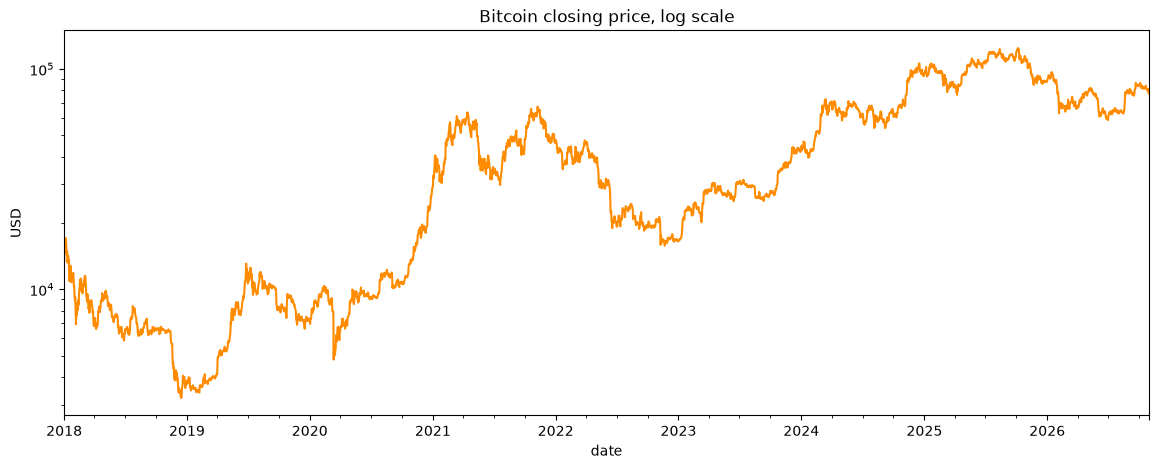

In [3]:
ax = btc["close"].plot(logy=True, color="darkorange", title="Bitcoin closing price, log scale")
ax.set_ylabel("USD")
plt.show()

A candlestick chart of the last three months, with 10- and 30-day moving averages:

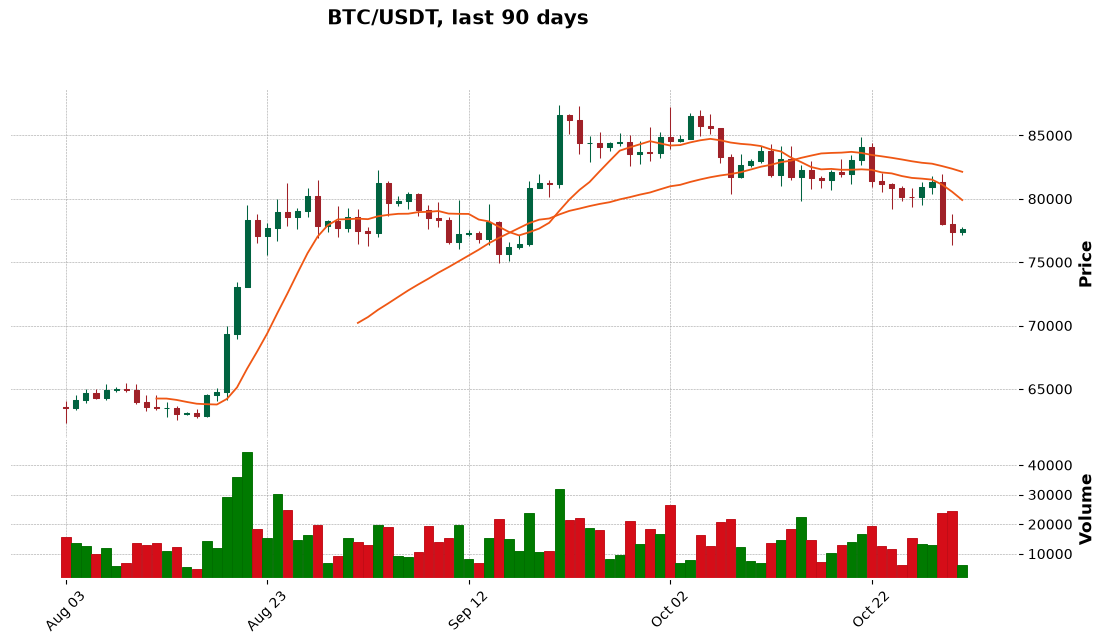

In [4]:
mpf.plot(btc.tail(90), type="candle", style="charles", volume=True, mav=(10, 30),
         figsize=(14, 7), title="BTC/USDT, last 90 days")

## 2. Trading volume: trend, weekly rhythm, and unusual days

Daily dollar volume, split into three parts: the slow **trend**, a repeating **weekly** pattern, and the **remainder**. A day whose remainder is far from normal (beyond 3 standard deviations) is unusual: something happened that the trend and the weekday don't explain. The analysis uses the last two years.

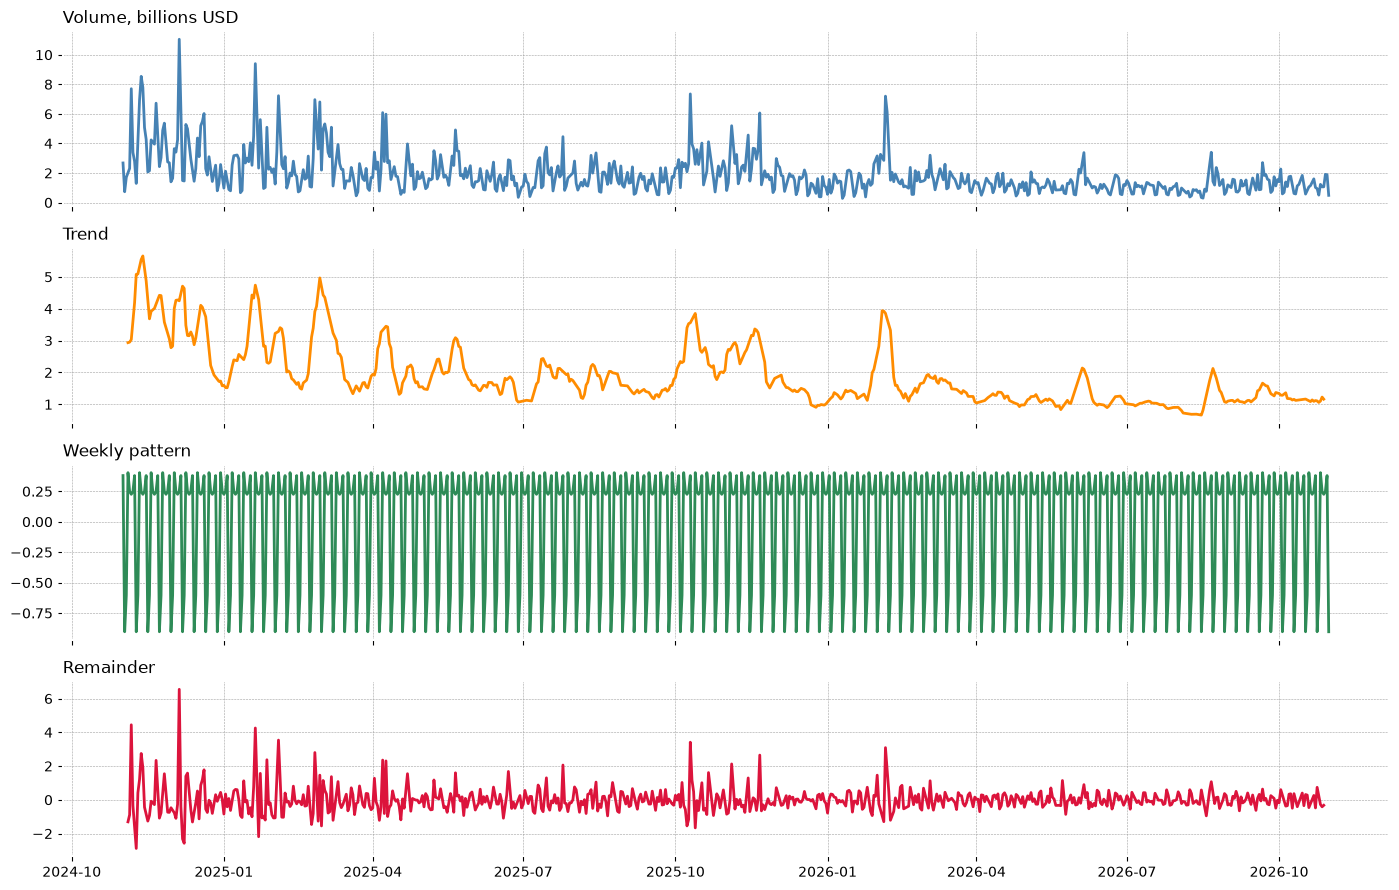

In [5]:
volume = btc["quote_volume"].loc["2024-11-01":] / 1e9   # billions of USD
parts = seasonal_decompose(volume, period=7)

fig, axes = plt.subplots(4, 1, figsize=(14, 9), sharex=True)
for ax, series, title, color in zip(axes,
        [parts.observed, parts.trend, parts.seasonal, parts.resid],
        ["Volume, billions USD", "Trend", "Weekly pattern", "Remainder"],
        ["steelblue", "darkorange", "seagreen", "crimson"]):
    ax.plot(series, color=color)
    ax.set_title(title, loc="left")
plt.tight_layout()
plt.show()

In [6]:
weekday = parts.seasonal.groupby(parts.seasonal.index.day_name()).mean()
order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
weekday.reindex(order).round(2).rename("difference from trend, billions USD")

date
Monday       0.40
Tuesday      0.25
Wednesday    0.23
Thursday     0.25
Friday       0.38
Saturday    -0.90
Sunday      -0.60
Name: difference from trend, billions USD, dtype: float64

In [7]:
resid = parts.resid.dropna()
unusual = resid[(resid - resid.mean()).abs() > 3 * resid.std()]
print(f"{len(unusual)} unusual days out of {len(resid)}")
pd.DataFrame({"volume, billions USD": volume[unusual.index].round(2),
              "close, USD": btc.loc[unusual.index, "close"].round(0)})

16 unusual days out of 724


,"volume, billions USD","close, USD"
date,,
2024-11-06,7.70,75572.0
2024-11-09,1.29,76677.0
2024-11-12,8.54,87952.0
2024-11-21,6.72,98317.0
2024-12-05,11.05,96946.0
2024-12-07,1.49,99832.0
2024-12-08,1.46,101110.0
2025-01-20,9.40,102260.0
2025-01-27,5.09,102083.0


Trading is clearly lighter on weekends: about \$0.9 billion below trend on Saturdays and \$0.6 billion on Sundays.

Most unusual days are spikes on big price moves: +8.9% the day after the 2024 US election, +8.2% in April 2025, −7.3% in October 2025, and −14% in February 2026. A few are the opposite, weekends that were even quieter than a usual weekend.

## 3. Predicting tomorrow

**What to predict.** Bitcoin in 2025–2026 traded far above anything in the earlier years, and a model trained on raw prices can't predict a level it has never seen. So the model predicts the **daily change** (the log return: roughly the percentage change), from the changes of the previous 30 days. A predicted change turns back into a price by applying it to today's close.

**Honest testing.**
- Train on 2018–2023, test on January 2024 to October 2026, a period the model never sees.
- Fit the scaling on the training years only.
- Compare with the naive guess **"tomorrow's price equals today's"**, which is famously hard to beat for prices.

In [8]:
returns = np.log(btc["close"]).diff().dropna()
WINDOW = 30

def make_windows(series):
    values = series.values
    x = np.array([values[i - WINDOW:i] for i in range(WINDOW, len(values))])
    y = values[WINDOW:]
    return x[..., None], y, series.index[WINDOW:]

split = "2024-01-01"
scale = returns[:split].std()               # from the training years only
x_all, y_all, dates = make_windows(returns / scale)
train = dates < split
x_train, y_train = x_all[train], y_all[train]
x_test, y_test, test_dates = x_all[~train], y_all[~train], dates[~train]
print(f"train: {len(x_train)} days, test: {len(x_test)} days")

train: 2160 days, test: 1035 days


In [9]:
model = models.Sequential([
    layers.Input(shape=(WINDOW, 1)),
    layers.LSTM(32),
    layers.Dropout(0.2),
    layers.Dense(1),
])
model.compile(optimizer="adam", loss="mse")
history = model.fit(x_train, y_train, epochs=30, batch_size=32, validation_split=0.15,
                    callbacks=[tf.keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)],
                    verbose=0)
print(f"trained for {len(history.history['loss'])} epochs")

trained for 13 epochs


In [10]:
predicted_return = model.predict(x_test, verbose=0).ravel() * scale
today = btc["close"].shift(1).loc[test_dates]          # the last price known when predicting
actual = btc["close"].loc[test_dates]
lstm_price = today * np.exp(predicted_return)
naive_price = today                                    # tomorrow equals today

def mae(pred):
    return (pred - actual).abs().mean()

actual_up = (actual > today)
results = pd.DataFrame({
    "average error, USD": [mae(naive_price), mae(lstm_price)],
    "direction right": ["-", f"{((lstm_price > today) == actual_up).mean():.1%}"],
}, index=["tomorrow equals today", "LSTM"])
print(f"Bitcoin went up on {actual_up.mean():.1%} of test days")
results.round(0)

Bitcoin went up on 50.5% of test days


,"average error, USD",direction right
tomorrow equals today,1354.0,-
LSTM,1357.0,49.9%


### Why the classic chart fools people

The chart below plots both forecasts against the real price for the test period. Both lines hug the real price almost perfectly, including the naive one, which knows nothing. At this scale, any forecast that starts from today's price looks brilliant.

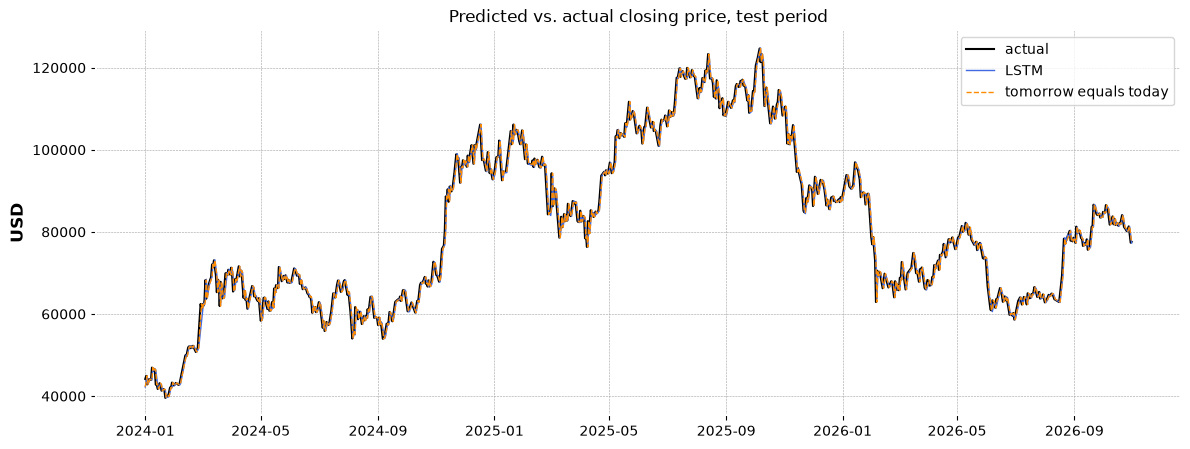

In [11]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(actual, color="black", lw=1.5, label="actual")
ax.plot(lstm_price, color="royalblue", lw=1, label="LSTM")
ax.plot(naive_price, color="darkorange", lw=1, ls="--", label="tomorrow equals today")
ax.set_title("Predicted vs. actual closing price, test period")
ax.set_ylabel("USD")
ax.legend()
plt.show()

The real test is the daily change itself. Here the model's predicted changes are compared with what actually happened:

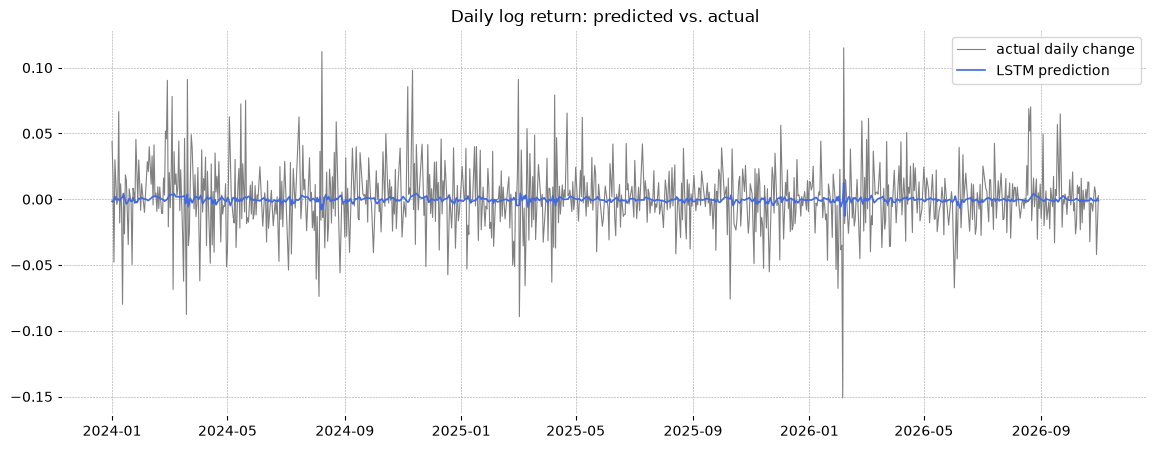

correlation between predicted and actual change: 0.057


In [12]:
fig, ax = plt.subplots(figsize=(14, 5))
actual_return = np.log(actual / today)
ax.plot(actual_return, color="gray", lw=0.8, label="actual daily change")
ax.plot(pd.Series(predicted_return, index=test_dates), color="royalblue", lw=1.2, label="LSTM prediction")
ax.set_title("Daily log return: predicted vs. actual")
ax.legend()
plt.show()
print(f"correlation between predicted and actual change: {np.corrcoef(predicted_return, actual_return)[0, 1]:.3f}")

## Results

- On 1,035 test days, the naive guess was off by \$1,354 a day on average and the LSTM by \$1,357. It hasn't learned anything that "tomorrow equals today" doesn't already know.
- It called the direction right on 49.9% of days, while Bitcoin simply went up on 50.5% of them. The correlation between its predicted and actual daily changes is 0.06, close to none.
- That's the expected outcome: if yesterday's prices could reliably predict tomorrow's, traders would already have traded the pattern away.

**The lesson:** a predicted-vs-actual price chart can't show forecasting skill, because the naive guess looks just as good on it. Always compare a model with a simple baseline, on days it hasn't seen.

## Tools

Python, pandas, NumPy, statsmodels (seasonal decomposition), TensorFlow / Keras (LSTM), matplotlib, mplfinance